TASK-4

cell 1:Organize content by release year

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/netflix_cleaned.csv")
print(df["release_year"].min(), "to", df["release_year"].max())
print("Total titles:", len(df))

1925 to 2021
Total titles: 8787


cell 2:calculate yearly content release

In [15]:
yearly = df.groupby("release_year").size()
print("Titles released before 2000:", yearly[yearly.index < 2000].sum())
print("Titles released from 2000 onwards:", yearly[yearly.index >= 2000].sum())

recent = yearly[yearly.index >= 2000]
recent.tail(10)

Titles released before 2000: 525
Titles released from 2000 onwards: 8262


release_year
2012     236
2013     286
2014     352
2015     555
2016     901
2017    1030
2018    1144
2019    1029
2020     953
2021     592
dtype: int64

cell 3:Identify growth and decline trends 

In [16]:
growth = (recent.pct_change() * 100).round(1)
print(growth.tail(10))
print("Peak year:", recent.idxmax(), "with", recent.max(), "titles")

release_year
2012    27.6
2013    21.2
2014    23.1
2015    57.7
2016    62.3
2017    14.3
2018    11.1
2019   -10.1
2020    -7.4
2021   -37.9
dtype: float64
Peak year: 2018 with 1144 titles


cell 4:create trend visualizations

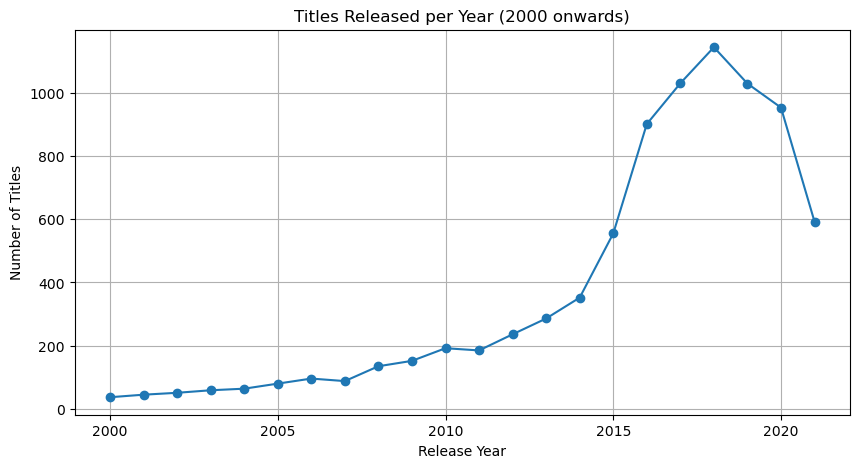

In [17]:
recent.plot(kind="line", marker="o", figsize=(10, 5))
plt.title("Titles Released per Year (2000 onwards)")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True)
plt.show()

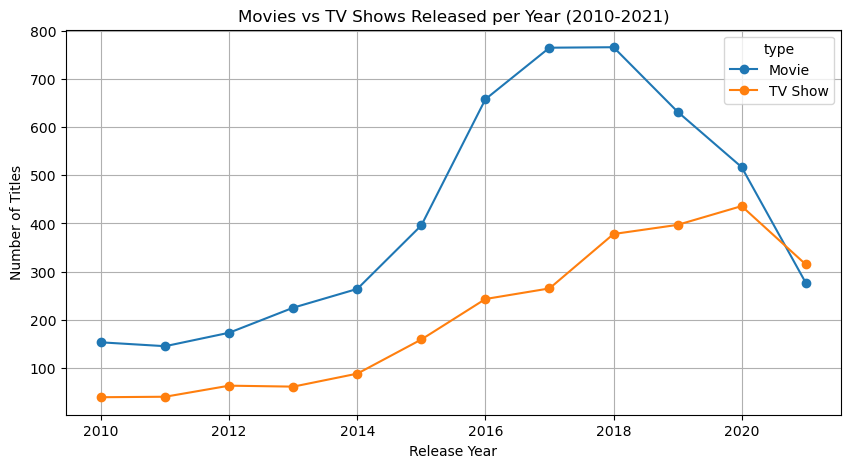

type,Movie,TV Show
release_year,,
2014,264,88
2015,396,159
2016,658,243
2017,765,265
2018,766,378
2019,632,397
2020,517,436
2021,277,315


In [18]:
type_by_year = pd.crosstab(df["release_year"], df["type"])
type_by_year.loc[2010:2021].plot(kind="line", marker="o", figsize=(10, 5))
plt.title("Movies vs TV Shows Released per Year (2010-2021)")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True)
plt.show()
type_by_year.loc[2014:2021]

cell 5:Interpret business patterns 

1.Most of the content is recent 70.6% of titles were released from 2015 onwards and only 525 titles were released before 2000.
2.Thos suggests that the netflix catalog is built mainly around new content rather than older titles.
3.Releases grew fast in 2015 (57.7% growth) and 2016 (62.2% growth) and reached a peak in 2018 with 1144 titles.
4.This suggests that netflix expanded its content quickly during these years inline with its push into original productions and its growth in many countries.
5.After 2018, releases fell by 10.1% in 2019 and 7.4% in 2020.
6.This may be because fewer recent titles had been added tothe catalog by the time the data was collected or because production slowed down in 2020.
7.The 2021 figure should be read carefully because the dataset only covers titles added upto september 2021.
8.This year is incomplete so the drop does not show a real decline.
9.Movies peaked in 2018 and fell to 277 in 2021 .
10. TV shows grew from 88 in 2014 to a peak of 436 in 2020 and in 2021 they passed movies .
11.This suggests that netflix has been shifting towards TV shows in recent years which matches thr Task2 finding that the TV show share of additions has been rising since 2018.

conclusion:Netflix catalog is mostly recent content,with a big jump in releases between 2015 and 2018 followed by a gradual fall.part of that fal may come from incomplete recent data.The growing share of TV shows suggests that series are becoming more important to netflix.  